In [ ]:
import numpy as np
import matplotlib

from matplotlib import pyplot as plt

from model import TempModel

In [2]:
#Set plotting look and feel

host_color = matplotlib.colors.to_rgb('#a8cee3')
path_color = matplotlib.colors.to_rgb('#ef777b')
cure_color = matplotlib.colors.to_rgb('#b2d987')

s_cmap = matplotlib.colors.LinearSegmentedColormap.from_list("", ["white", host_color])
i_cmap = matplotlib.colors.LinearSegmentedColormap.from_list("", ["white", path_color])

matplotlib.rcParams['figure.dpi'] = 600
matplotlib.rcParams['text.usetex'] = True

plt.rcParams.update({
    'text.usetex': True,
    'font.family': 'Helvetica'
})

In [13]:
def temp_sim(t1=26, t2=32, inc=0.1, mode='default'):
    max_temps = np.arange(t1, t2, inc)

    cure_freq = np.zeros(len(max_temps))
    sus_freq = np.zeros(len(max_temps))
    prev_eco = np.zeros(len(max_temps))
    prev_evo = np.zeros(len(max_temps))

    for i, max_temp in enumerate(max_temps):
        print(i/len(max_temps), end="\r")

        model_eco = TempModel(temp_min=5, temp_max=max_temp, n_years=100, t_max=max_temp, mode=mode)
        model_evo = TempModel(temp_min=5, temp_max=max_temp, n_years=400, S1=450, S2=450, cost2=1.05, res2=1.5, mode=mode)
            
        model_eco.solve()
        model_evo.solve()

        S_eco = model_eco.annual_mean('S1')[-1]
        I_eco = model_eco.annual_mean('I1')[-1]
        C_eco = model_eco.annual_mean('C1')[-1]
        N_eco = S_eco + I_eco + C_eco

        S1_evo = model_evo.annual_mean('S1')[-1]
        I1_evo = model_evo.annual_mean('I1')[-1]
        C1_evo = model_evo.annual_mean('C1')[-1]

        S2_evo = model_evo.annual_mean('S2')[-1]
        I2_evo = model_evo.annual_mean('I2')[-1]
        C2_evo = model_evo.annual_mean('C2')[-1]
        N_evo = S1_evo + I1_evo + C1_evo + S2_evo + I2_evo + C2_evo

        trans_inds = np.intersect1d(
            np.where(model_eco.t > 98 * 365), 
            np.where(model_eco.temp(model_evo.t) > model_eco.trans_threshold))
        
        cure_freq[i] = np.average(model_eco.C1[trans_inds] / (model_eco.C1[trans_inds] + model_eco.I1[trans_inds]))
        
        sus_freq[i] = (S2_evo + I2_evo + C2_evo) / N_evo
        prev_eco[i] = (I_eco + C_eco) / N_eco
        prev_evo[i] = (I1_evo + C1_evo + I2_evo + C2_evo) / N_evo

    return (max_temps, cure_freq, sus_freq, prev_eco, prev_evo)

In [22]:
max_temps, cure_freq, sus_freq, prev_eco, prev_evo = temp_sim()

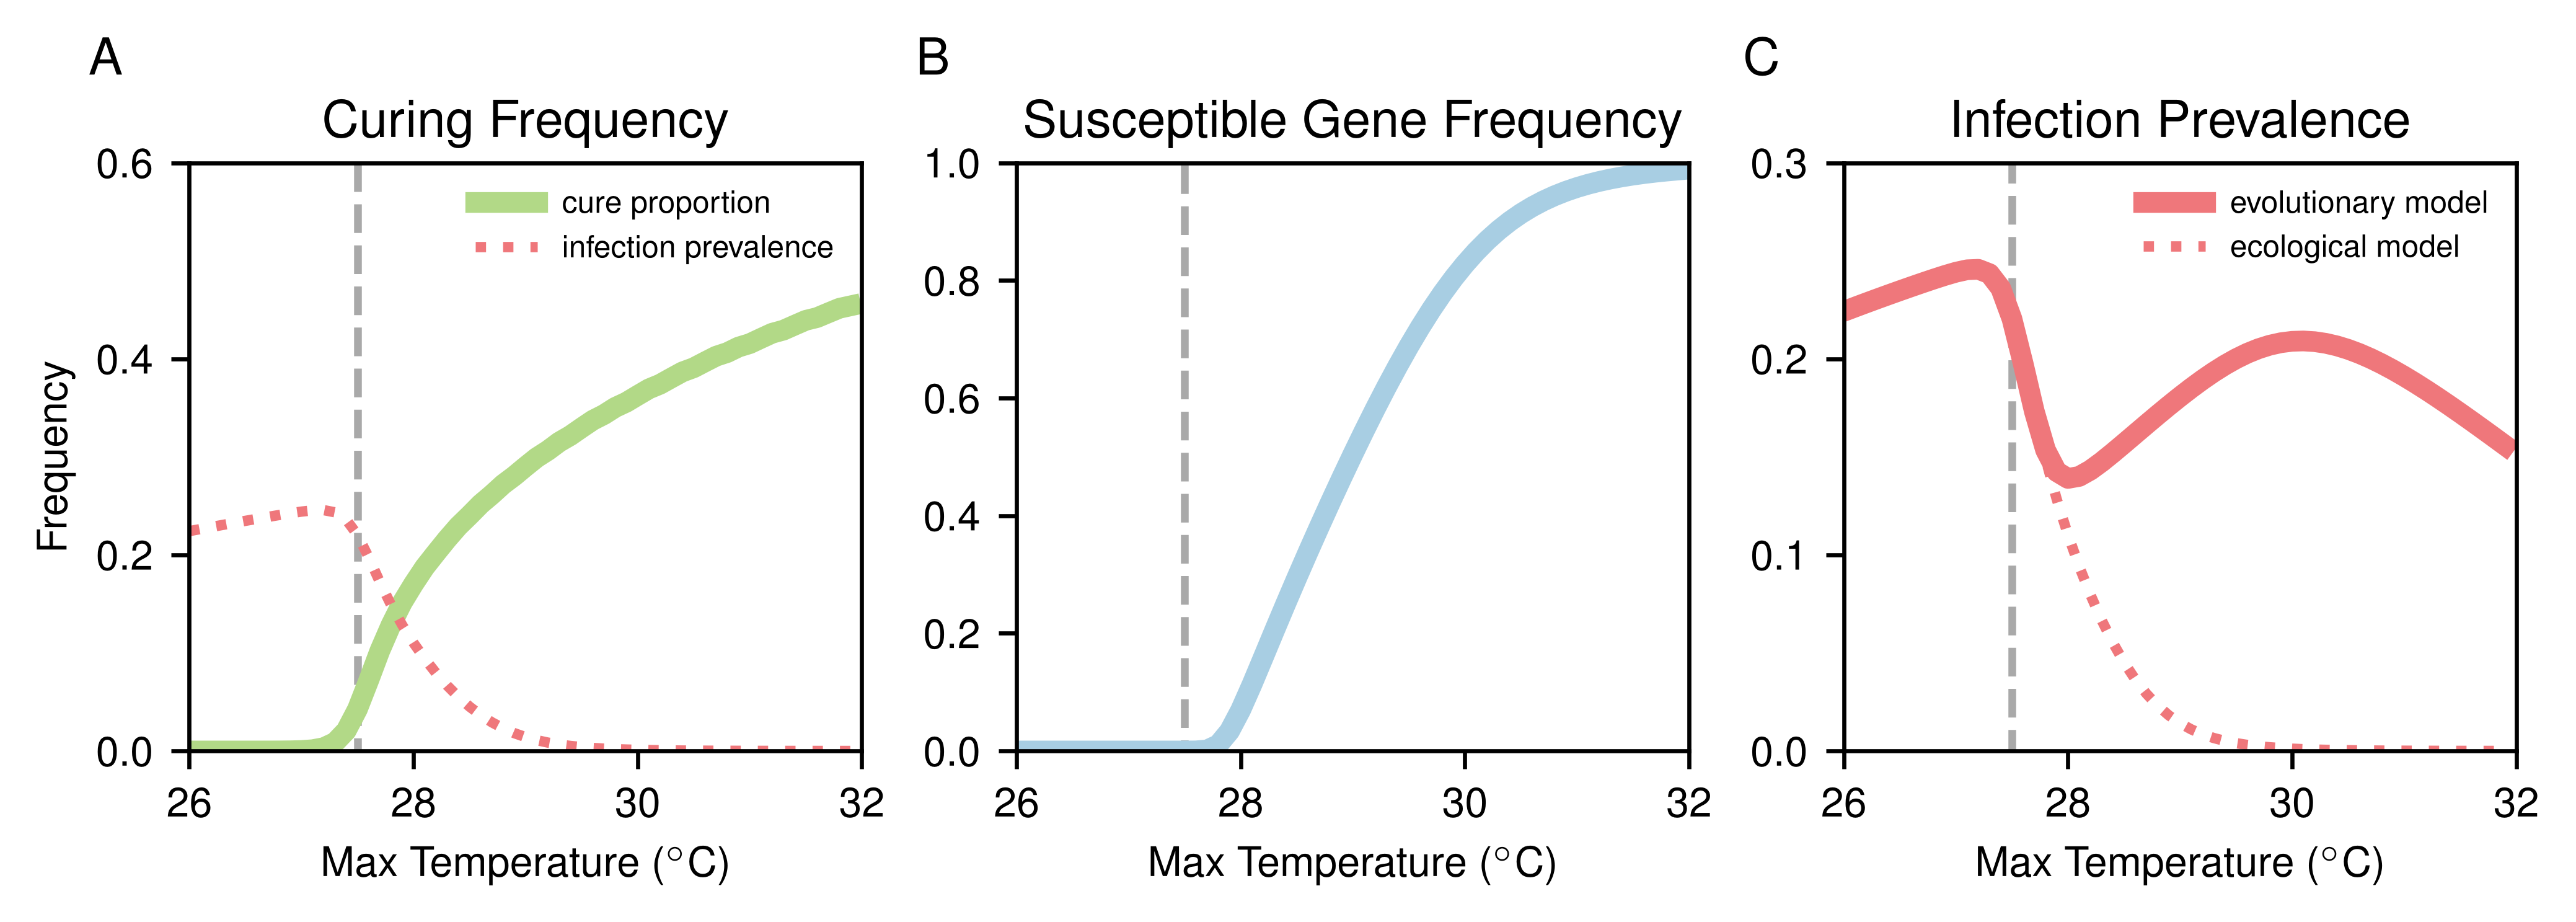

In [27]:
mm = 1/25.4
max_tempsfig, ax = plt.subplots(ncols=3, nrows=1, figsize=(173*mm, 60*mm), layout='constrained')

ax[0].vlines(27.5, ymin=-0.1, ymax=1.1, color='darkgrey', linestyle='dashed')
ax[1].vlines(27.5, ymin=-0.1, ymax=1.1, color='darkgrey', linestyle='dashed')
ax[2].vlines(27.5, ymin=-0.1, ymax=1.1, color='darkgrey', linestyle='dashed')

ax[0].tick_params(axis='both', which='major', labelsize=8)
ax[1].tick_params(axis='both', which='major', labelsize=8)
ax[2].tick_params(axis='both', which='major', labelsize=8)

ax[0].plot(max_temps, cure_freq, color=cure_color, linewidth=4, label='cure proportion')
ax[0].plot(max_temps, prev_eco, color=path_color, linestyle='dotted', linewidth=2, label='infection prevalence')

ax[1].plot(max_temps, sus_freq, color=host_color, linewidth=4)

ax[2].plot(max_temps, prev_evo, color=path_color, linewidth=4, label='evolutionary model')
ax[2].plot(max_temps, prev_eco, color=path_color, linestyle=':', linewidth=2, label='ecological model')

ax[0].set_title('Curing Frequency', pad=5, size=10)
ax[1].set_title('Susceptible Gene Frequency', pad=5, size=10)
ax[2].set_title('Infection Prevalence', pad=5, size=10)

ax[0].set_ylim(0, 0.6)
ax[1].set_ylim(0, 1)
ax[2].set_ylim(0, 0.3)

ax[0].set_xlim(26, 32)
ax[1].set_xlim(26, 32)
ax[2].set_xlim(26, 32)

ax[0].set_ylabel('Frequency', size=8)

ax[0].set_yticks((0, 0.2, 0.4, 0.6))
ax[1].set_yticks((0, 0.2, 0.4, 0.6, 0.8, 1))
ax[2].set_yticks((0, 0.1, 0.2, 0.3))

for axis in ax.reshape(-1):
    axis.yaxis.set_major_formatter(matplotlib.ticker.FormatStrFormatter('%.1f'))
    axis.xaxis.set_major_formatter(matplotlib.ticker.FormatStrFormatter('%.0f'))

ax[0].set_xlabel(r'Max Temperature ($^\circ$C)', size=8)
ax[1].set_xlabel(r'Max Temperature ($^\circ$C)', size=8)
ax[2].set_xlabel(r'Max Temperature ($^\circ$C)', size=8)

ax[0].annotate("A", xy=(-0.15, 1.15), xycoords="axes fraction", fontsize=10)
ax[1].annotate("B", xy=(-0.15, 1.15), xycoords="axes fraction", fontsize=10)
ax[2].annotate("C", xy=(-0.15, 1.15), xycoords="axes fraction", fontsize=10)

ax[0].legend(frameon=False, fontsize=6, loc=1)
ax[2].legend(frameon=False, fontsize=6, loc=1)

In [20]:
def find_threshold(low, high, n_iter, count=0, sus=1.5, temp=27):
    if count == n_iter:
        return low

    else:
        mid = low + ((high - low) / 2)
        model = TempModel(temp_min=5, temp_max=temp, n_years=400, S1=450, S2=450, cost2=mid, res2=sus)
        model.solve()

        prop = (model.annual_mean('S2')[-1] + model.annual_mean('I2')[-1] + model.annual_mean('C2')[-1]) / (
            model.annual_mean('S1')[-1] + model.annual_mean('I1')[-1] + model.annual_mean('C1')[-1] +
            model.annual_mean('S2')[-1] + model.annual_mean('I2')[-1] + model.annual_mean('C2')[-1])

        if prop > 0.05:
            return(find_threshold(low, mid, n_iter, count=count+1, sus=sus, temp=temp))
        elif prop <= 0.05:
            return(find_threshold(mid, high, n_iter, count=count+1, sus=sus, temp=temp))

In [54]:
temp_vals = np.linspace(26, 30, 30)
sus_vals = [1.25, 1.5, 1.75, 2]
thresholds = np.zeros([len(sus_vals), len(temp_vals)])

n_sims = len(sus_vals)*len(temp_vals)

for i, sus in enumerate(sus_vals):
    for j, temp in enumerate(temp_vals):
        print((i*len(temp_vals)+j)/n_sims, end="\r")
        thresholds[i, j] = find_threshold(1, 1.4, 7, sus=sus, temp=temp)

In [ ]:
import pickle

with open('threshold.pkl', 'rb') as file:
    thresholds = pickle.load(file)

temp_vals = np.linspace(26, 30, 30)

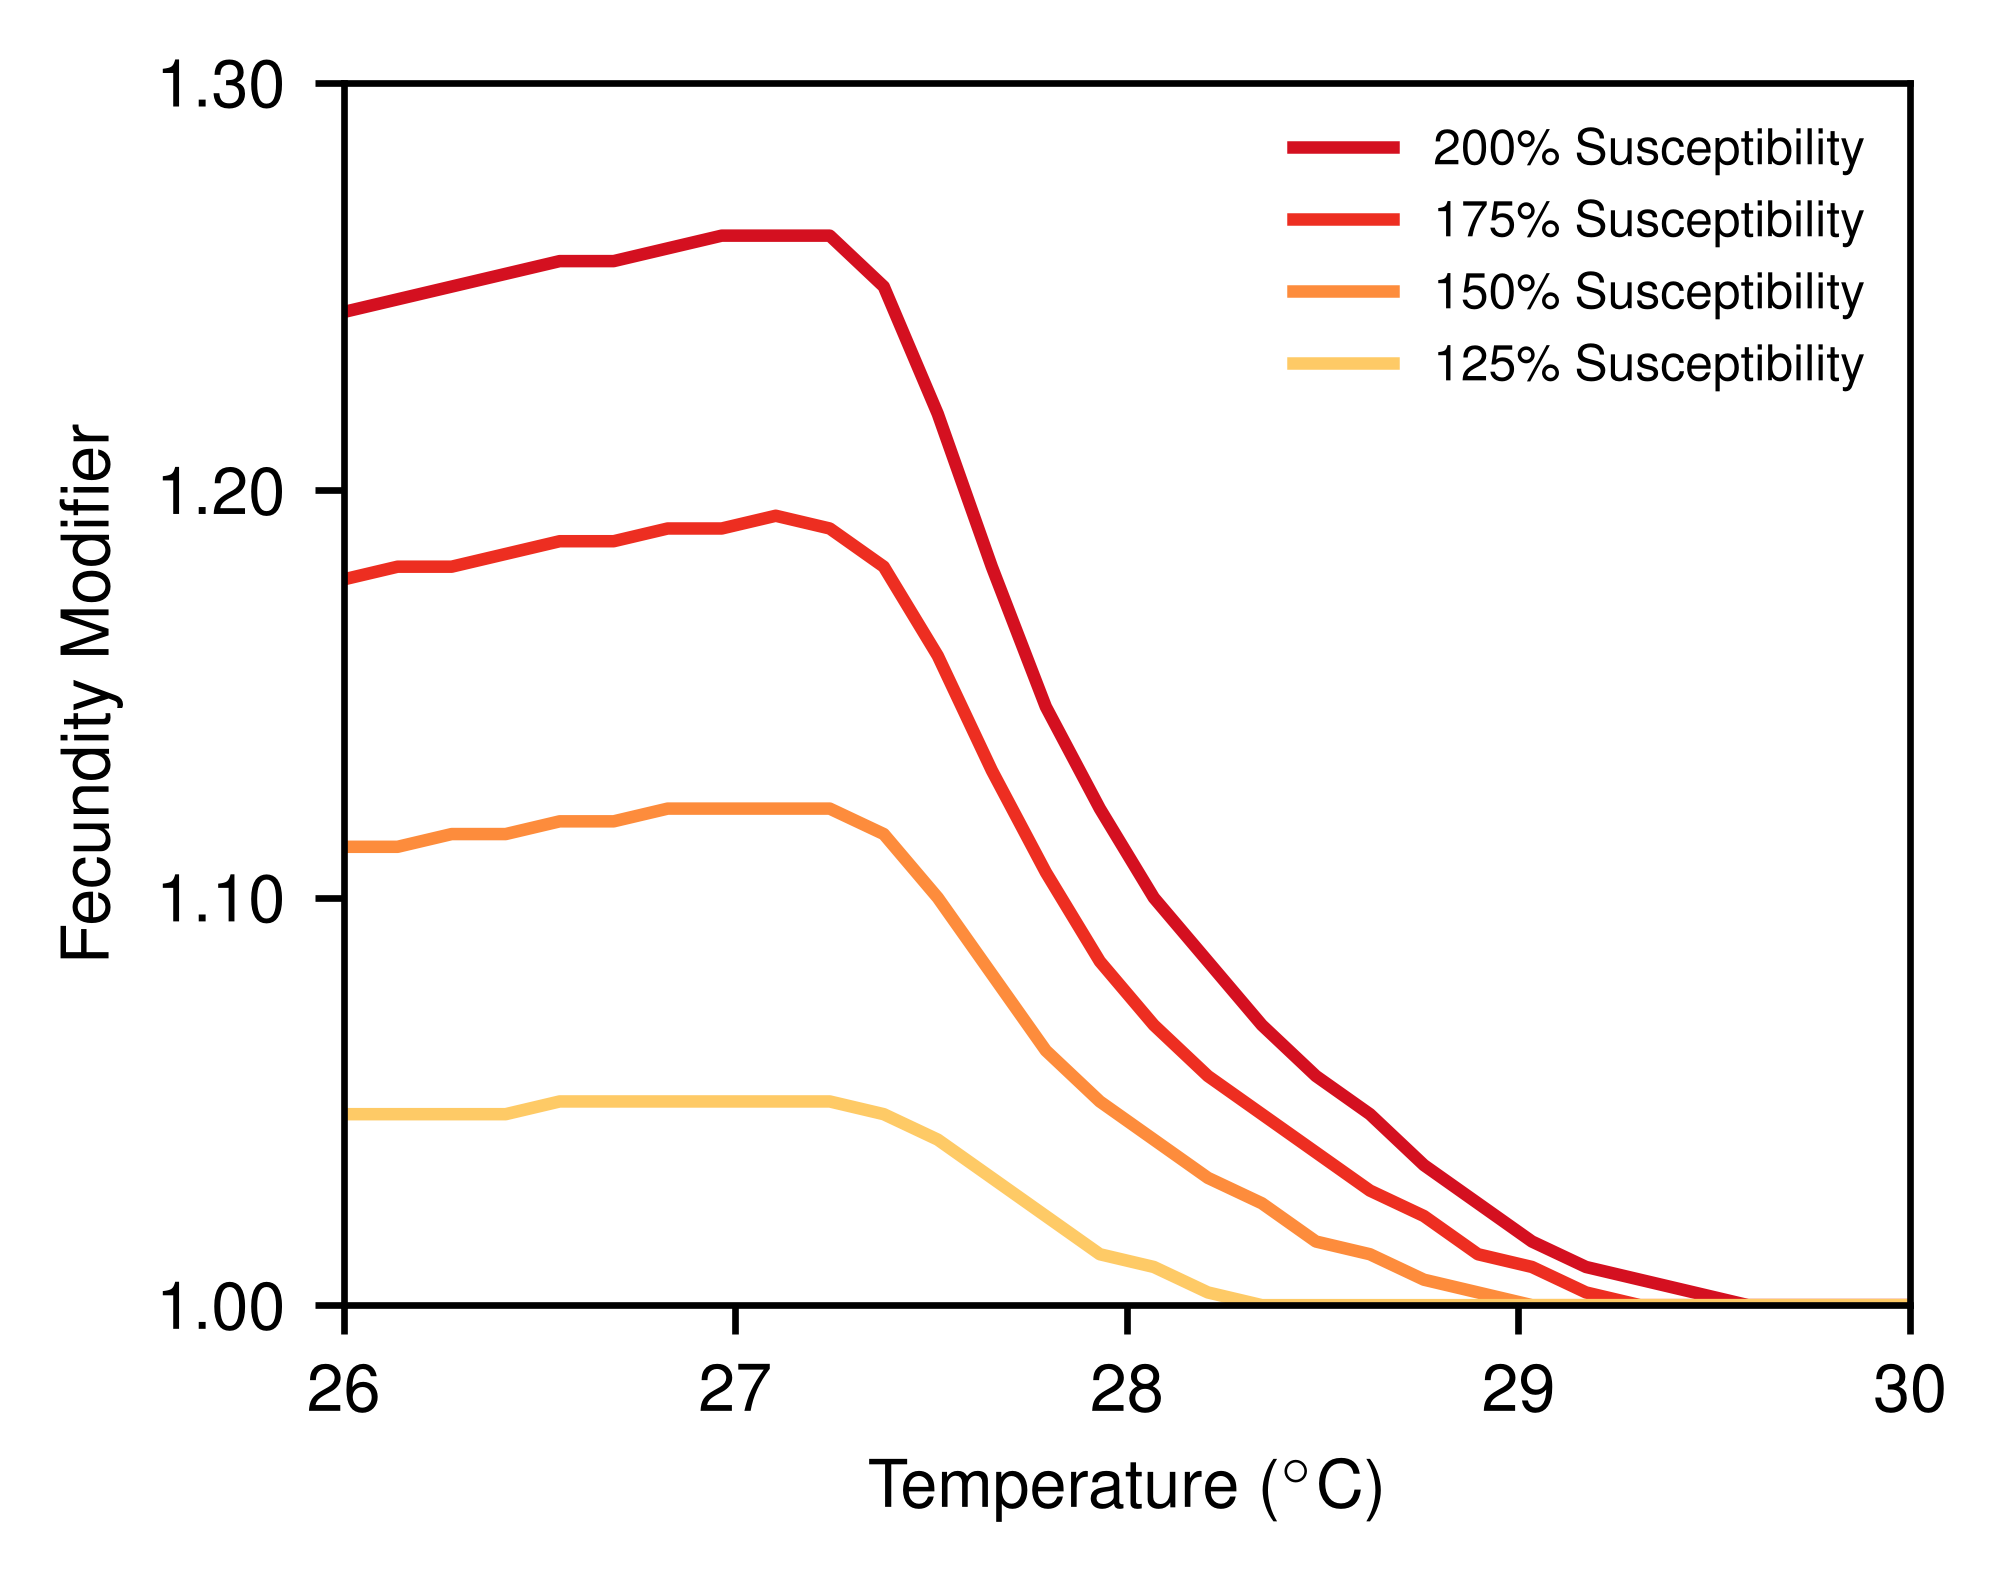

In [ ]:
import matplotlib as mpl
mm = 1/25.4
max_tempsfig, ax = plt.subplots(ncols=1, nrows=1, figsize=(82*mm, 64*mm), layout='constrained')

cmap = mpl.colormaps['YlOrRd']

ax.plot(temp_vals, thresholds[3, :], color=cmap(0.8), label='200\\% Susceptibility')
ax.plot(temp_vals, thresholds[2, :], color=cmap(0.7), label='175\\% Susceptibility')
ax.plot(temp_vals, thresholds[1, :], color=cmap(0.5), label='150\\% Susceptibility')
ax.plot(temp_vals, thresholds[0, :], color=cmap(0.3), label='125\\% Susceptibility')

ax.tick_params(axis='both', which='major', labelsize=8)

ax.set_xlabel(r'Temperature ($^\circ$C)', fontsize=8)
ax.set_ylabel('Fecundity Modifier', fontsize=8)

ax.set_yticks((1, 1.1, 1.2, 1.3))
ax.yaxis.set_major_formatter(matplotlib.ticker.FormatStrFormatter('%.2f'))
ax.xaxis.set_major_formatter(matplotlib.ticker.FormatStrFormatter('%.0f'))

ax.set_ylim(1, 1.3)
ax.set_xlim(26, 30)

ax.legend(frameon=False, fontsize=6)

In [91]:
import pickle

with open('threshold.pkl', 'wb') as file:
    pickle.dump(thresholds, file)

In [15]:
max_temps_vir, cure_freq_vir, sus_freq_vir, prev_eco_vir, prev_evo_vir = temp_sim(mode='vir')

In [21]:
max_temps_trans, cure_freq_trans, sus_freq_trans, prev_eco_trans, prev_evo_trans = temp_sim(mode='trans')

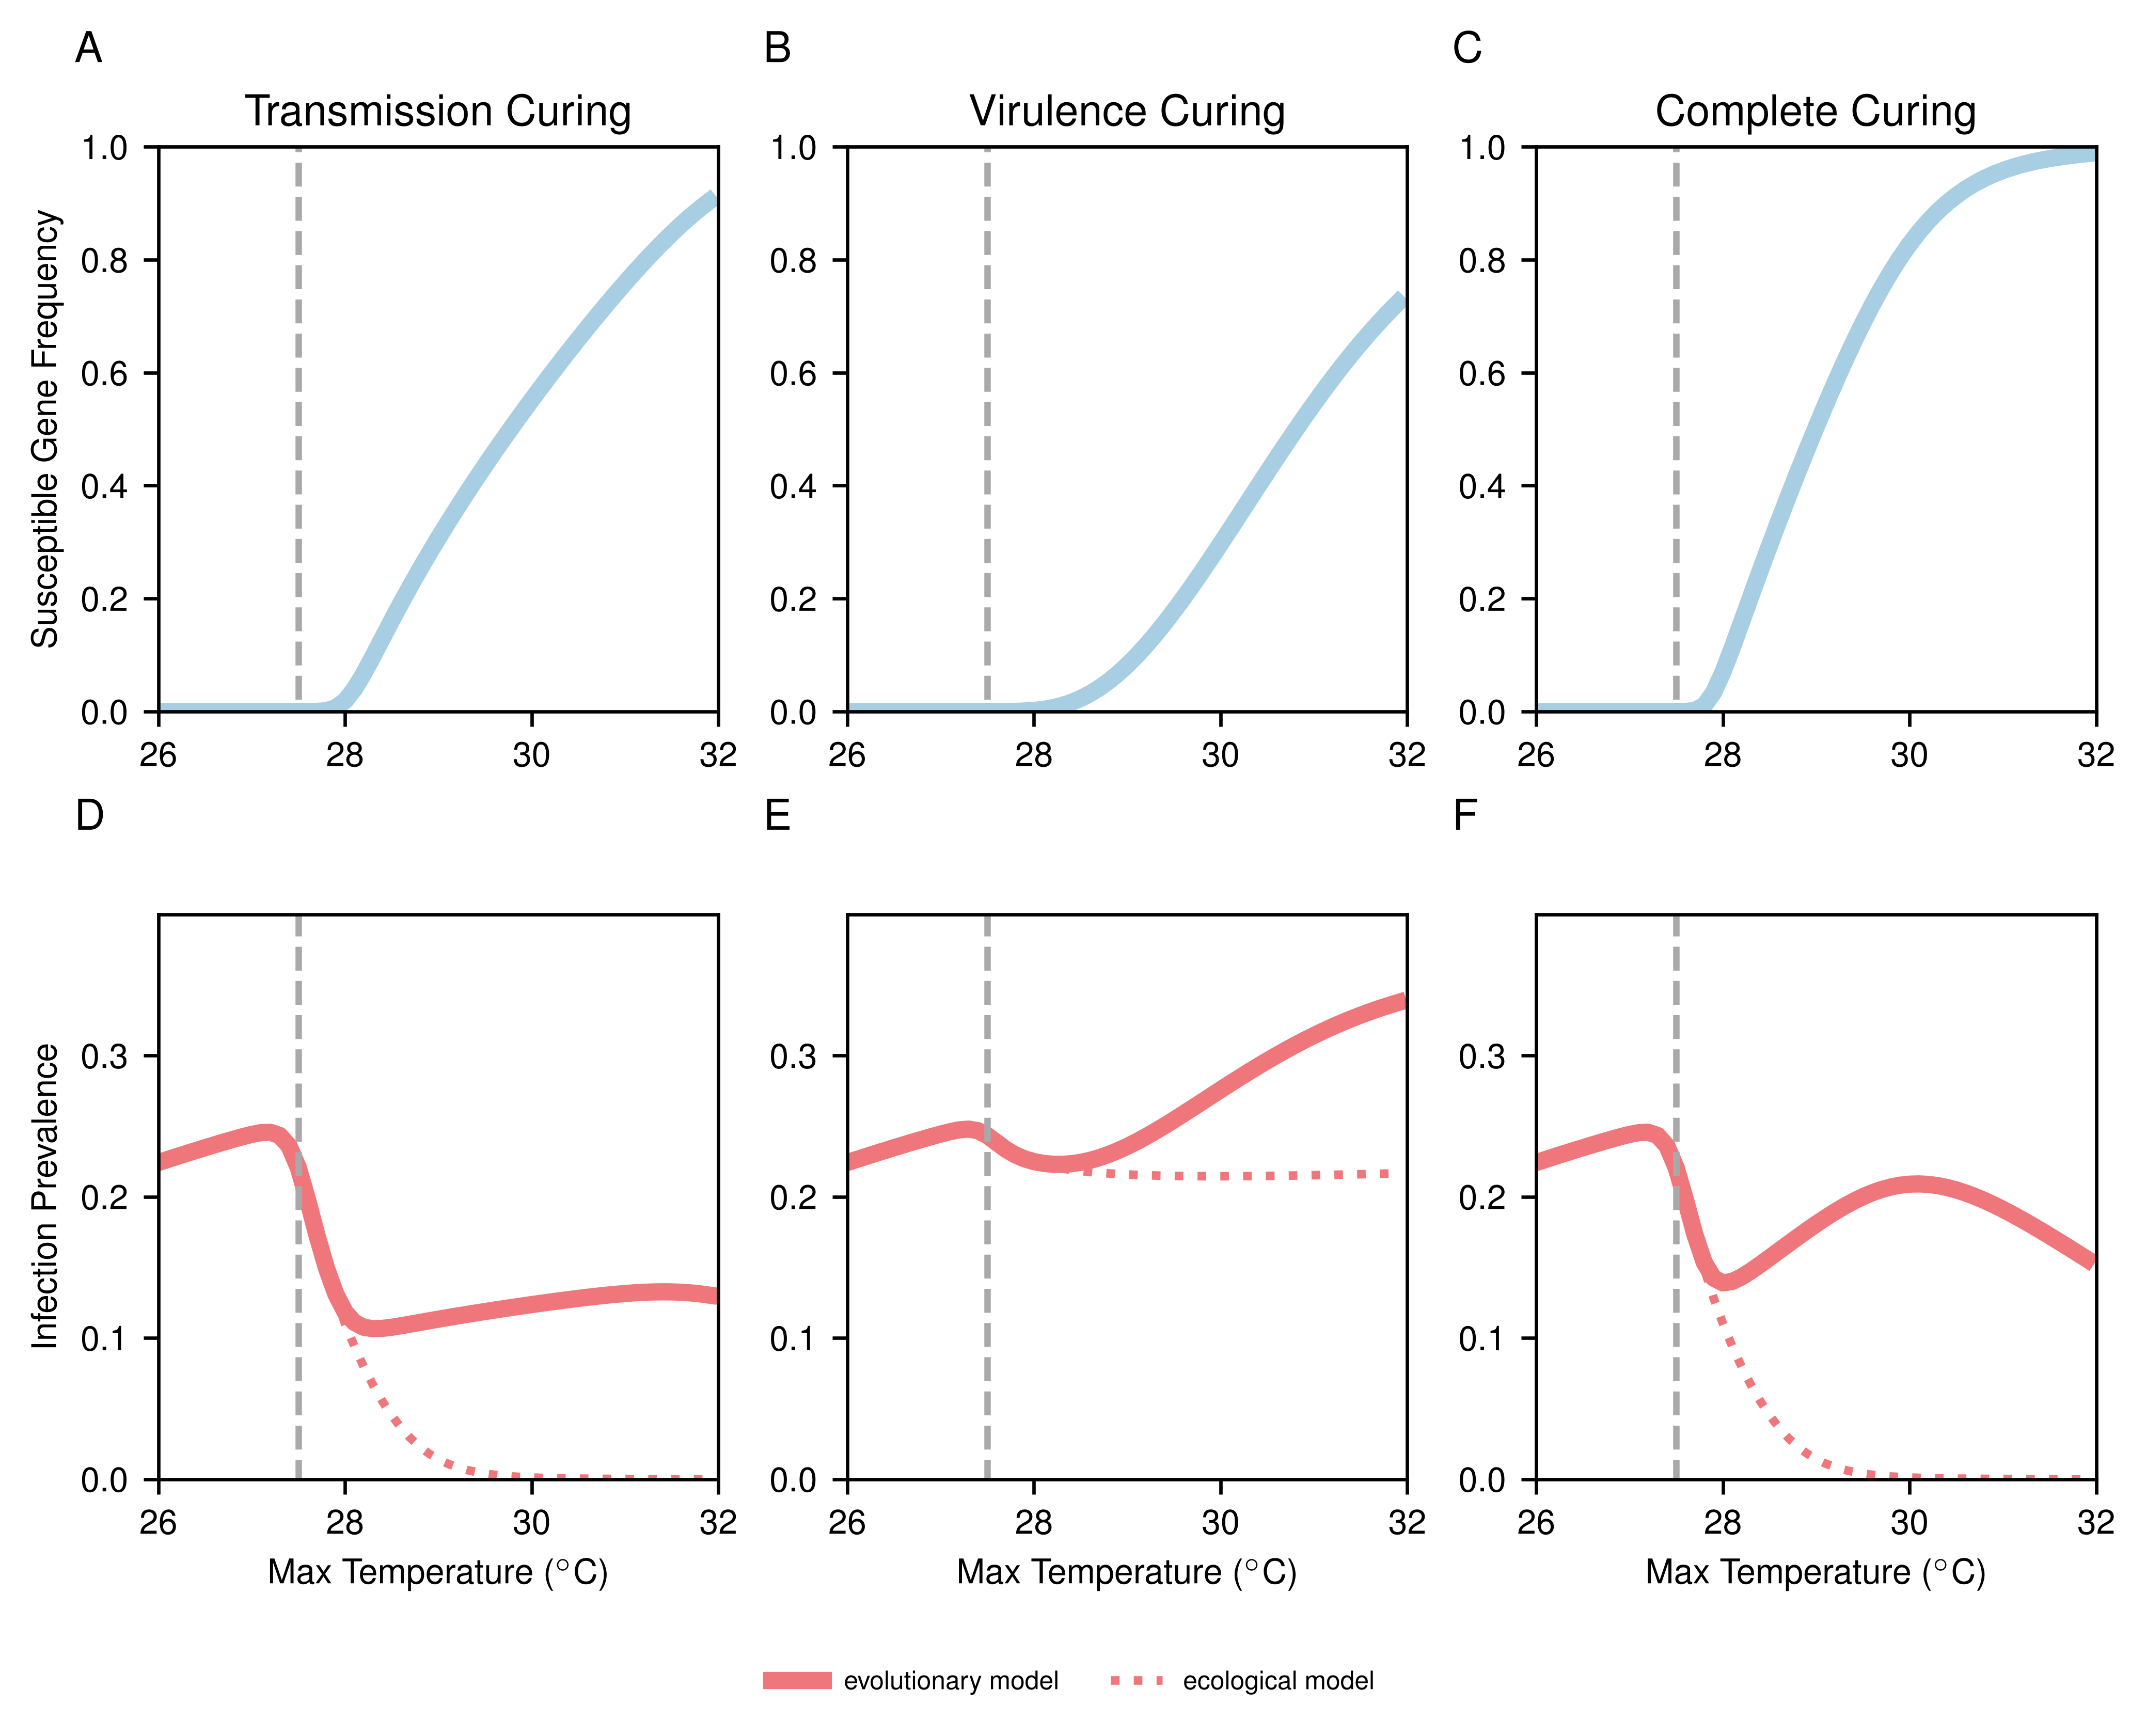

In [ ]:
mm = 1/25.4
fig, ax = plt.subplots(ncols=3, nrows=2, figsize=(173*mm, 130*mm), layout='constrained')

ax[0,0].plot(max_temps, sus_freq_vir, color=host_color, linewidth=4)
ax[0,1].plot(max_temps, sus_freq_trans, color=host_color, linewidth=4)
ax[0,2].plot(max_temps, sus_freq, color=host_color, linewidth=4)

ax[1,0].plot(max_temps, prev_evo_vir, color=path_color, linewidth=4, label='evolutionary model')
ax[1,0].plot(max_temps, prev_eco_vir, color=path_color, linestyle=':', linewidth=2, label='ecological model')
ax[1,1].plot(max_temps, prev_evo_trans, color=path_color, linewidth=4, label='evolutionary model')
ax[1,1].plot(max_temps, prev_eco_trans, color=path_color, linestyle=':', linewidth=2, label='ecological model')
ax[1,2].plot(max_temps, prev_evo, color=path_color, linewidth=4, label='evolutionary model')
ax[1,2].plot(max_temps, prev_eco, color=path_color, linestyle=':', linewidth=2, label='ecological model')

ax[0,0].set_title('Transmission Curing', pad=5, size=10)
ax[0,1].set_title('Virulence Curing', pad=5, size=10)
ax[0,2].set_title('Complete Curing', pad=5, size=10)

ax[0,0].set_ylim(0, 1)
ax[0,1].set_ylim(0, 1)
ax[0,2].set_ylim(0, 1)

ax[1,0].set_ylim(0, 0.4)
ax[1,1].set_ylim(0, 0.4)
ax[1,2].set_ylim(0, 0.4)

ax[0,0].set_ylabel('Susceptible Gene Frequency', size=8)
ax[1,0].set_ylabel('Infection Prevalence', size=8)

ax[1,0].set_xlabel(r'Max Temperature ($^\circ$C)', size=8)
ax[1,1].set_xlabel(r'Max Temperature ($^\circ$C)', size=8)
ax[1,2].set_xlabel(r'Max Temperature ($^\circ$C)', size=8)

ax[0,0].set_yticks((0, 0.2, 0.4, 0.6, 0.8, 1))
ax[0,1].set_yticks((0, 0.2, 0.4, 0.6, 0.8, 1))
ax[0,2].set_yticks((0, 0.2, 0.4, 0.6, 0.8, 1))

ax[1,0].set_yticks((0, 0.1, 0.2, 0.3))
ax[1,1].set_yticks((0, 0.1, 0.2, 0.3))
ax[1,2].set_yticks((0, 0.1, 0.2, 0.3))

for axis in ax.reshape(-1):
    axis.set_xlim(26, 32)
    axis.vlines(27.5, ymin=-0.1, ymax=1.1, color='darkgrey', linestyle='dashed')
    axis.tick_params(axis='both', which='major', labelsize=8)
    axis.yaxis.set_major_formatter(matplotlib.ticker.FormatStrFormatter('%.1f'))
    axis.xaxis.set_major_formatter(matplotlib.ticker.FormatStrFormatter('%.0f'))

ax[0,0].annotate("A", xy=(-0.15, 1.15), xycoords="axes fraction", fontsize=10)
ax[0,1].annotate("B", xy=(-0.15, 1.15), xycoords="axes fraction", fontsize=10)
ax[0,2].annotate("C", xy=(-0.15, 1.15), xycoords="axes fraction", fontsize=10)
ax[1,0].annotate("D", xy=(-0.15, 1.15), xycoords="axes fraction", fontsize=10)
ax[1,1].annotate("E", xy=(-0.15, 1.15), xycoords="axes fraction", fontsize=10)
ax[1,2].annotate("F", xy=(-0.15, 1.15), xycoords="axes fraction", fontsize=10)

lines, labels = ax[1,0].get_legend_handles_labels()
fig.legend(lines, labels, ncol=3, loc='center', bbox_to_anchor=(0.5, -0.05), frameon=False, fontsize=6)